In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.cluster import KMeans,AgglomerativeClustering , DBSCAN
from sklearn.decomposition import PCA 
from sklearn.datasets import make_blobs,make_moons
from sklearn.preprocessing import StandardScaler

Text(0.5, 1.0, 'Unlabeled Data (make_blobs)')

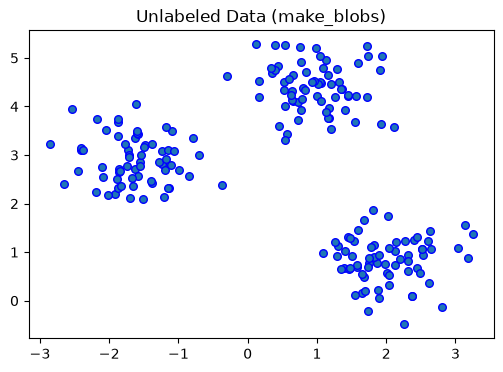

In [19]:
# Unsupervised learning is a type of machine learning where the model is trained on unlabeled data. The goal is to find hidden patterns or intrinsic structures in the input data. Clustering is a common unsupervised learning technique that groups similar data points together based on their features.

# 1) Generate unlabeled data using make_blobs and make_moons functions from sklearn.datasets. These functions create synthetic datasets that can be used for clustering.

x, y = make_blobs(n_samples=200, centers=3, cluster_std=0.50, random_state=0)

# See the generated data using a scatter plot. The x variable contains the features of the data points, while the y variable contains the true labels (which we won't use for clustering).
plt.figure(figsize=(6, 4))
plt.scatter(x[:, 0], x[:, 1], s=30, edgecolors='blue')
plt.title('Unlabeled Data (make_blobs)')

In [20]:
# apply k-means clustering

k_means = KMeans(n_clusters=4, random_state=1, n_init=10)
k_means.fit(x)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",1
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 2)","[[ 2.4

In [21]:
# seeing centroids of clusters
centroids = k_means.cluster_centers_
print("Centroids of clusters:\n", centroids) # x,y pts (FINAL centroids of clusters)

Centroids of clusters:
 [[ 2.49226735  1.04120485]
 [-1.62597658  2.89784482]
 [ 0.96573445  4.39663084]
 [ 1.70344901  0.69833047]]


C:\Users\moham\AppData\Local\Temp\ipykernel_14360\2525669510.py:3: UserWarning: You passed an edgecolor/edgecolors ('blue') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(centroids[:, 0], centroids[:, 1], s=30, edgecolors='blue', marker='x', linewidths=2)


Text(0.5, 1.0, 'Unlabeled Data with K-Means Centroids')

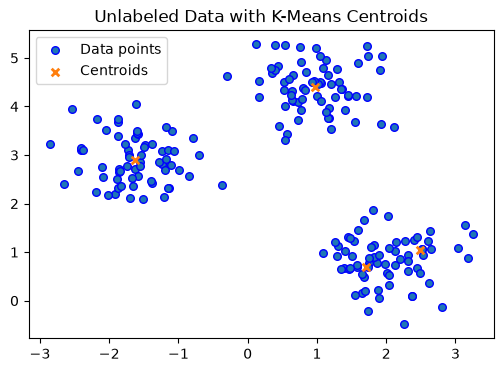

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(x[:, 0], x[:, 1], s=30, edgecolors='blue')
plt.scatter(centroids[:, 0], centroids[:, 1], s=30, edgecolors='blue', marker='x', linewidths=2)
plt.legend(['Data points', 'Centroids'], loc='best')
plt.title('Unlabeled Data with K-Means Centroids')

Text(0.5, 1.0, 'Elbow Method for Optimal k')

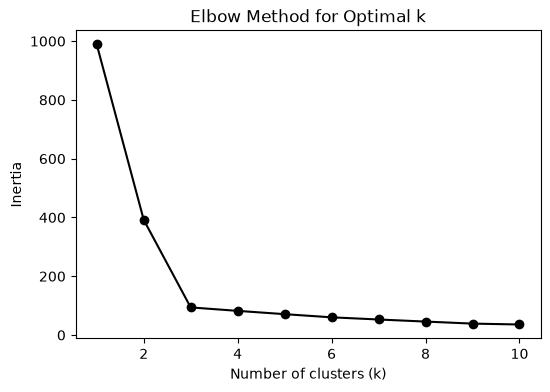

In [25]:
# Choosing the best K (elbow method)

k_range = range(1, 11)
inertia = []

for k in k_range:
    k_means = KMeans(n_clusters=k, random_state=1, n_init=10)
    k_means.fit(x)
    inertia.append(k_means.inertia_) # saving inertia for each k value
    
# plot the elbow curve
plt.figure(figsize=(6, 4))
plt.plot(k_range, inertia, marker='o', color='black')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')

# therfore the best k value is 3 as the elbow point is at k=3. This means that the optimal number of clusters for this dataset is 3

In [ ]:
print(inertia)
# Notice that the inertia decreases as the number of clusters increases, but the rate of decrease slows down after k=3.

[988.5764434481495, 392.01247585424255, 93.99874702328015, 82.22824190932414, 71.0399719196489, 60.273043625347434, 52.9011509694022, 45.80294641369599, 38.88891252226989, 35.865664358248736]


In [28]:
# Customer segmentation ex

np.random.seed(7)

centers = [[30, 20], [30, 80], [60, 50], [85, 20], [85, 80]]
x_customers = np.vstack([np.random.randn(30,2)*7 + center for center in centers])

x_customers

array([[41.83367993, 16.73843841],
       [30.22974115, 22.85261398],
       [24.4775388 , 20.01445901],
       [29.9937673 ,  7.71692986],
       [37.12360604, 24.20348961],
       [25.62199718, 18.79916217],
       [33.53709562, 18.17050509],
       [28.30075645,  9.82731011],
       [33.88206218, 20.86716634],
       [31.92121947,  9.31432828],
       [41.55489784, 21.08034875],
       [27.2900204 , 34.20350555],
       [29.68229779,  9.84524911],
       [27.16340501,  3.98179429],
       [37.34577585, 17.08467977],
       [24.80212532, 27.50729092],
       [18.44247087, 23.74800549],
       [15.54909638, 15.36488462],
       [21.57046108, 30.23382939],
       [42.36312615, 17.69410374],
       [35.8851327 , 18.74009519],
       [33.97643321, 14.73013963],
       [18.04162558,  7.37830939],
       [32.68185296, 35.73316537],
       [31.88588141, 16.32776766],
       [43.38413204, 21.66111293],
       [30.7100379 , 21.76804415],
       [29.07335962, 17.83366562],
       [19.95525574,

In [ ]:
k_means_customers = KMeans(n_clusters=5, random_state=42)
k_means_customers.fit(x_customers)
labels_customers = k_means_customers.labels_

In [30]:
print(labels_customers) # cluster labels for each customer data point

[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3]


C:\Users\moham\AppData\Local\Temp\ipykernel_14360\466423570.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


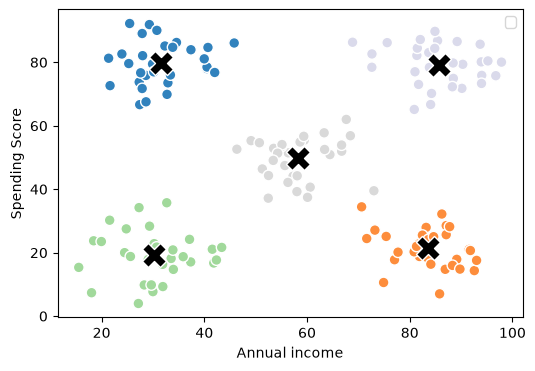

Clusters found
Green : Low Income Low spending = Careful
Blue: Low Income High spending
off-white: middle Income middle spending
orange:high income low spend
gray:high income high spend


In [34]:
plt.figure(figsize=(6,4))
plt.scatter(x_customers[:,0],x_customers[:,1],c=labels_customers,cmap="tab20c",s=60,edgecolors="white")

plt.scatter(k_means_customers.cluster_centers_[:,0],k_means_customers.cluster_centers_[:,1],marker="X",s=300,edgecolors="white",c="black")
plt.xlabel("Annual income")
plt.ylabel("Spending Score")
plt.legend()
plt.show()

print("Clusters found")
print("Green : Low Income Low spending = Careful")
print("Blue: Low Income High spending")
print("off-white: middle Income middle spending")
print("orange:high income low spend")
print("gray:high income high spend")

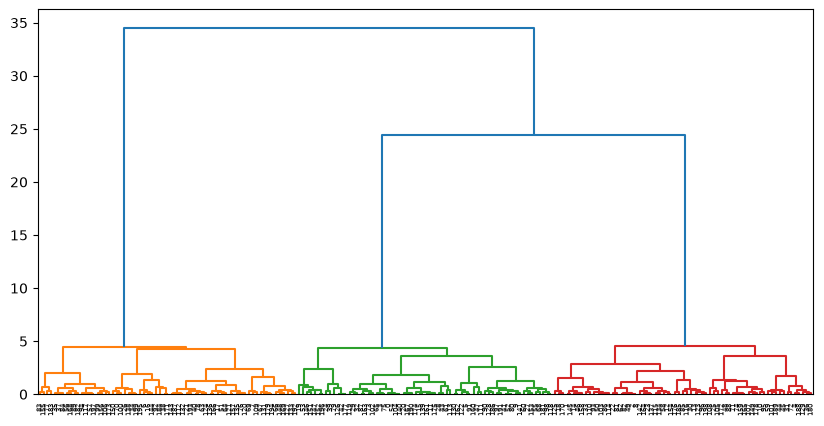

In [ ]:
# Hierarchical clustering (Dendrogram)
from scipy.cluster.hierarchy import dendrogram, linkage

z = linkage(x, method='ward')
# linkage() function performs hierarchical clustering on the data. The 'ward' method minimizes the variance of merged clusters.
plt.figure(figsize=(10, 5))
dendrogram(z) # draws dendrogram
plt.show()

In [ ]:
# DSBCAN clustering is a density-based clustering algorithm that groups together points that are closely packed together, while marking points that lie alone in low-density regions as outliers. It is particularly useful for datasets with clusters of varying shapes and sizes.

x_moons = make_moons(n_samples=200, noise=0.05, random_state=0)[0]
dbscan_moons = DBSCAN(eps=0.2, min_samples=5)
dbscan_moons.fit(x_moons)

# just for comparision 
km_moon = KMeans(n_clusters=2, random_state=0)
km_moon.fit(x_moons)

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",0.2
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",5
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"components_ components_: ndarray of shape (n_core_samples, n_features)Copy of each core sample found by training.","ndarray[float64](199, 2)","[[ 0.82, 0.52], [ 1.62,-0.38], [-0.02, 0.27], ..., [ 0.18,-0.01], [ 0.12, 1.01], [ 1.62,-0.22]]"
"core_sample_indices_ core_sample_indices_: ndarray of shape (n_core_samples,)Indices of core samples.","ndarray[int64](199,)","[ 0, 1, 2,...,197,198,199]"


Text(0.5, 1.0, 'DBSCAN Clustering on Moons')

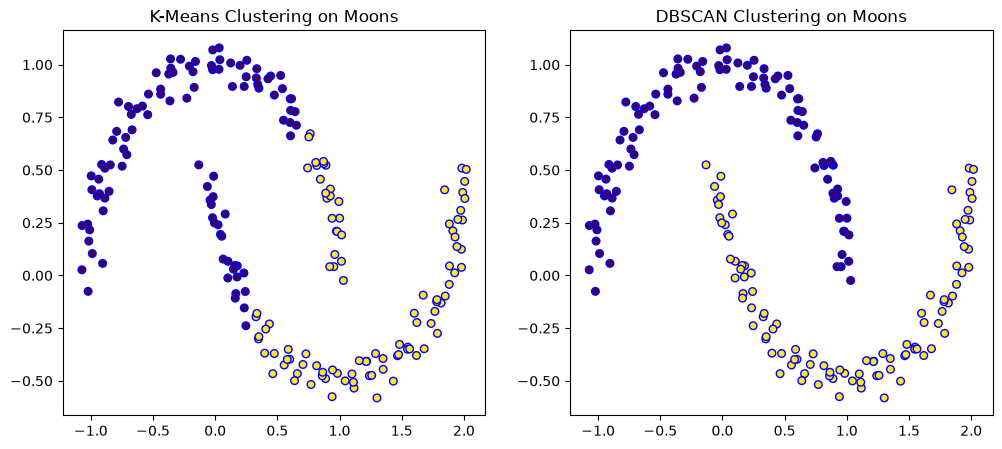

In [ ]:
# Comparing between K-means and DBSCAN clustering on the moons dataset (weird shapes)
fig , axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].scatter(x_moons[:, 0], x_moons[:, 1], c=km_moon.labels_, cmap='viridis', s=30, edgecolors='blue')
axs[0].set_title('K-Means Clustering on Moons')

axs[1].scatter(x_moons[:, 0], x_moons[:, 1], c=dbscan_moons.labels_, cmap='viridis', s=30, edgecolors='blue')
axs[1].set_title('DBSCAN Clustering on Moons')

# Notice that K-means fails to capture the non-linear structure of the moons dataset, while DBSCAN successfully identifies the two distinct clusters. This demonstrates the advantage of using density-based clustering methods like DBSCAN for datasets with complex shapes.

In [ ]:
# PCA: Principal Component Analysis (PCA) is a dimensionality reduction technique that transforms high-dimensional data into a lower-dimensional space while preserving as much variance as possible.
from sklearn.datasets import load_iris

iris = load_iris()
x = iris.data
y = iris.target

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
pca = PCA(n_components=2) # reduce the data to 2 dimensions for visualization
x_pca = pca.fit_transform(x_scaled)

In [58]:
print(x.shape)
print(x_pca.shape) # red. from 4 to 2 features

# print the explained variance ratio to see how much information (variance) is retained in the reduced dimensions 
print(pca.explained_variance_ratio_)

(150, 4)
(150, 2)
[0.72962445 0.22850762]


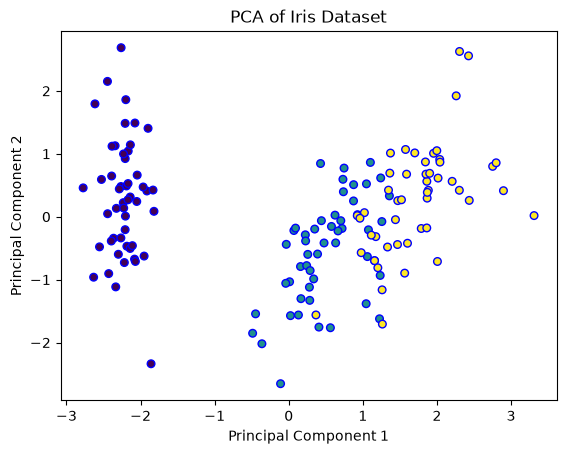

In [ ]:
# Visualize the PCA results using a scatter plot, coloring the points by their true labels (species of iris).

plt.scatter(x_pca[:, 0], x_pca[:, 1], c=y, cmap='viridis', s=30, edgecolors='blue')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Iris Dataset')
plt.show()